In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
np.random.seed(42)
n = 200
it_services = pd.DataFrame({
    "Inquiry_ID": range(1, n + 1),
    "Service_Type": np.random.choice(["Technical Support", "Software Installation", "Network Issue", "Hardware Support", "Cloud Service"], n),
    "Department": np.random.choice(["IT", "HR", "Finance", "Marketing", "Sales"], n),
    "Priority": np.random.choice(["Low", "Medium", "High"], n),
    "Status": np.random.choice(["Resolved", "Pending", "In Progress"], n),
    "Response_Time_Hours": np.random.randint(1, 49, n),
    "Resolution_Time_Hours": np.random.randint(2, 73, n)
})
it_services.head()

,Inquiry_ID,Service_Type,Department,Priority,Status,Response_Time_Hours,Resolution_Time_Hours
0,1,Hardware Support,HR,High,Resolved,16,36
1,2,Cloud Service,Finance,Low,Pending,8,2
2,3,Network Issue,IT,Medium,Resolved,4,41
3,4,Cloud Service,IT,Low,In Progress,40,65
4,5,Cloud Service,Marketing,Low,Resolved,4,23


In [3]:
digital_services = pd.DataFrame({
    "Inquiry_ID": range(1, n + 1),
    "Digital_Service": np.random.choice(["Website Development", "Cloud Storage", "Web Hosting", "Digital Marketing", "Software Solutions"], n),
    "Channel": np.random.choice(["Website", "Email", "Phone", "Social Media"], n),
    "Customer_Type": np.random.choice(["Student", "Individual", "Business"], n),
    "Inquiry_Status": np.random.choice(["Completed", "Pending", "Cancelled"], n),
    "Satisfaction_Score": np.random.randint(1, 6, n)
})
digital_services.head()

,Inquiry_ID,Digital_Service,Channel,Customer_Type,Inquiry_Status,Satisfaction_Score
0,1,Web Hosting,Social Media,Student,Pending,1
1,2,Digital Marketing,Website,Student,Pending,3
2,3,Digital Marketing,Email,Individual,Completed,5
3,4,Software Solutions,Social Media,Business,Pending,5
4,5,Software Solutions,Email,Student,Completed,3


In [4]:
service_requests = pd.DataFrame({
    "Request_ID": range(1, n + 1),
    "Customer_ID": np.random.randint(1001, 1061, n),
    "Request_Type": np.random.choice(["Complaint", "Technical Help", "General Inquiry", "Service Request"], n),
    "Priority": np.random.choice(["Low", "Medium", "High"], n),
    "Status": np.random.choice(["Open", "In Progress", "Closed"], n),
    "Request_Date": pd.date_range("2026-01-01", periods=n, freq="D")
})
service_requests.head()

,Request_ID,Customer_ID,Request_Type,Priority,Status,Request_Date
0,1,1035,Complaint,Low,Closed,2026-01-01
1,2,1044,General Inquiry,Medium,In Progress,2026-01-02
2,3,1034,Complaint,Low,Open,2026-01-03
3,4,1033,General Inquiry,Low,In Progress,2026-01-04
4,5,1055,Technical Help,Medium,Open,2026-01-05


In [5]:
print("IT Service Dataset:", it_services.shape)
print("Digital Service Dataset:", digital_services.shape)
print("Customer Request Dataset:", service_requests.shape)
print("\nIT Service Information:")
it_services.info()
print("\nDigital Service Information:")
digital_services.info()
print("\nCustomer Request Information:")
service_requests.info()

IT Service Dataset: (200, 7)
Digital Service Dataset: (200, 6)
Customer Request Dataset: (200, 6)

IT Service Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Inquiry_ID             200 non-null    int64
 1   Service_Type           200 non-null    str  
 2   Department             200 non-null    str  
 3   Priority               200 non-null    str  
 4   Status                 200 non-null    str  
 5   Response_Time_Hours    200 non-null    int32
 6   Resolution_Time_Hours  200 non-null    int32
dtypes: int32(2), int64(1), str(4)
memory usage: 16.1 KB

Digital Service Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Inquiry_ID          200 non-null    int64
 1   Digital_

In [6]:
datasets = [it_services, digital_services, service_requests]
for df in datasets:
    df.drop_duplicates(inplace=True)
    for column in df.select_dtypes(include="object").columns:
        df[column] = df[column].fillna("Unknown")
print("Data cleaning completed!")
print("IT Service Missing Values:", it_services.isnull().sum().sum())
print("Digital Service Missing Values:", digital_services.isnull().sum().sum())
print("Customer Request Missing Values:", service_requests.isnull().sum().sum())

Data cleaning completed!
IT Service Missing Values: 0
Digital Service Missing Values: 0
Customer Request Missing Values: 0


C:\Users\my pc\AppData\Local\Temp\ipykernel_1796\1445928156.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in df.select_dtypes(include="object").columns:
C:\Users\my pc\AppData\Local\Temp\ipykernel_1796\1445928156.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide

In [7]:
it_service_analysis = it_services.groupby("Service_Type").agg(
    Total_Inquiries=("Inquiry_ID", "count"),
    Average_Response_Time=("Response_Time_Hours", "mean"),
    Average_Resolution_Time=("Resolution_Time_Hours", "mean")
).reset_index()
print(it_service_analysis.round(2))

            Service_Type  Total_Inquiries  Average_Response_Time  \
0          Cloud Service               36                  22.69   
1       Hardware Support               49                  23.59   
2          Network Issue               37                  26.35   
3  Software Installation               35                  22.91   
4      Technical Support               43                  22.12   

   Average_Resolution_Time  
0                    38.72  
1                    37.61  
2                    35.73  
3                    38.26  
4                    36.63  


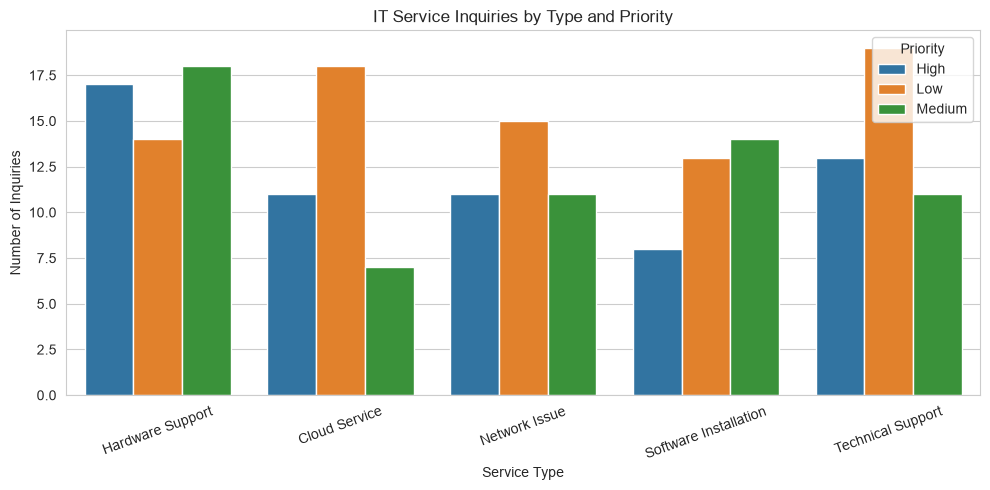

In [8]:
plt.figure(figsize=(10, 5))
sns.countplot(data=it_services, x="Service_Type", hue="Priority")
plt.title("IT Service Inquiries by Type and Priority")
plt.xlabel("Service Type")
plt.ylabel("Number of Inquiries")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [9]:
digital_analysis = digital_services.groupby("Digital_Service").agg(
    Total_Inquiries=("Inquiry_ID", "count"),
    Average_Satisfaction=("Satisfaction_Score", "mean")
).reset_index()
print(digital_analysis.round(2))

       Digital_Service  Total_Inquiries  Average_Satisfaction
0        Cloud Storage               47                  2.79
1    Digital Marketing               32                  3.28
2   Software Solutions               41                  3.15
3          Web Hosting               40                  2.98
4  Website Development               40                  2.68


        Channel  Total_Inquiries  Average_Satisfaction
0         Email               51                  3.10
1         Phone               44                  3.00
2  Social Media               45                  2.87
3       Website               60                  2.87


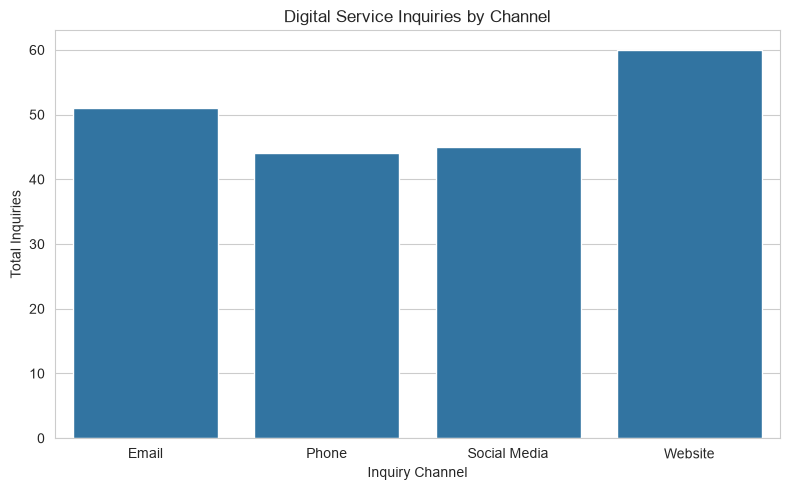

In [10]:
channel_analysis = digital_services.groupby("Channel").agg(
    Total_Inquiries=("Inquiry_ID", "count"),
    Average_Satisfaction=("Satisfaction_Score", "mean")
).reset_index()
print(channel_analysis.round(2))
plt.figure(figsize=(8, 5))
sns.barplot(data=channel_analysis, x="Channel", y="Total_Inquiries")
plt.title("Digital Service Inquiries by Channel")
plt.xlabel("Inquiry Channel")
plt.ylabel("Total Inquiries")
plt.tight_layout()
plt.show()

       Request_Type       Status  Total_Requests
0         Complaint       Closed              20
1         Complaint  In Progress              20
2         Complaint         Open              19
3   General Inquiry       Closed              18
4   General Inquiry  In Progress              14
5   General Inquiry         Open              11
6   Service Request       Closed               9
7   Service Request  In Progress              16
8   Service Request         Open              23
9    Technical Help       Closed              12
10   Technical Help  In Progress              21
11   Technical Help         Open              17


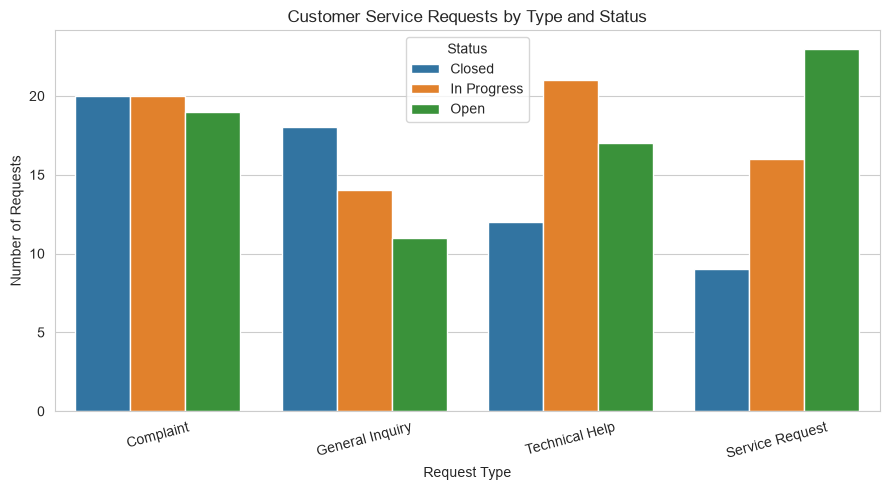

In [11]:
request_analysis = service_requests.groupby(["Request_Type", "Status"]).size().reset_index(name="Total_Requests")
print(request_analysis)
plt.figure(figsize=(9, 5))
sns.countplot(data=service_requests, x="Request_Type", hue="Status")
plt.title("Customer Service Requests by Type and Status")
plt.xlabel("Request Type")
plt.ylabel("Number of Requests")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [12]:
customer_segments = service_requests.groupby("Customer_ID").agg(
    Total_Requests=("Request_ID", "count"),
    High_Priority_Requests=("Priority", lambda x: (x == "High").sum()),
    Closed_Requests=("Status", lambda x: (x == "Closed").sum())
).reset_index()
customer_segments["Customer_Segment"] = np.where(
    customer_segments["Total_Requests"] >= 5, "Frequent Customer",
    np.where(customer_segments["Total_Requests"] >= 3, "Regular Customer", "Occasional Customer")
)
print(customer_segments.head(10))

   Customer_ID  Total_Requests  High_Priority_Requests  Closed_Requests  \
0         1001               2                       1                0   
1         1002               6                       2                2   
2         1003               7                       2                4   
3         1004               3                       1                3   
4         1005               3                       0                1   
5         1006               5                       3                1   
6         1007               3                       0                0   
7         1008               6                       2                1   
8         1009               3                       2                1   
9         1010               1                       1                0   

      Customer_Segment  
0  Occasional Customer  
1    Frequent Customer  
2    Frequent Customer  
3     Regular Customer  
4     Regular Customer  
5    Frequent Customer  

            Service_Type  Total_Demand
0       Hardware Support            49
1      Technical Support            43
2          Network Issue            37
3          Cloud Service            36
4  Software Installation            35


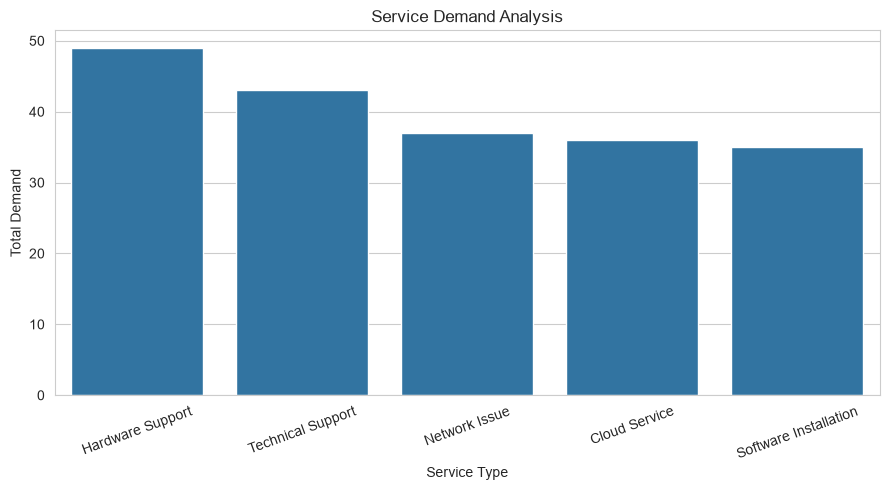

In [13]:
service_demand = it_services["Service_Type"].value_counts().reset_index()
service_demand.columns = ["Service_Type", "Total_Demand"]
print(service_demand)
plt.figure(figsize=(9, 5))
sns.barplot(data=service_demand, x="Service_Type", y="Total_Demand")
plt.title("Service Demand Analysis")
plt.xlabel("Service Type")
plt.ylabel("Total Demand")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [14]:
top_it_service = service_demand.iloc[0]["Service_Type"]
top_digital_service = digital_analysis.loc[digital_analysis["Total_Inquiries"].idxmax(), "Digital_Service"]
top_channel = channel_analysis.loc[channel_analysis["Total_Inquiries"].idxmax(), "Channel"]
average_satisfaction = digital_services["Satisfaction_Score"].mean()
print("BUSINESS INSIGHTS")
print("-----------------------------")
print("Most Demanded IT Service:", top_it_service)
print("Most Popular Digital Service:", top_digital_service)
print("Most Used Inquiry Channel:", top_channel)
print("Average Customer Satisfaction:", round(average_satisfaction, 2), "/ 5")
print("Total Customer Requests:", len(service_requests))

BUSINESS INSIGHTS
-----------------------------
Most Demanded IT Service: Hardware Support
Most Popular Digital Service: Cloud Storage
Most Used Inquiry Channel: Website
Average Customer Satisfaction: 2.96 / 5
Total Customer Requests: 200


In [15]:
it_service_analysis.to_csv("day37_it_service_analysis.csv", index=False)
digital_analysis.to_csv("day37_digital_service_analysis.csv", index=False)
request_analysis.to_csv("day37_customer_request_analysis.csv", index=False)
customer_segments.to_csv("day37_customer_segmentation.csv", index=False)
service_demand.to_csv("day37_service_demand_analysis.csv", index=False)
with open("day37_business_insights_report.txt", "w") as file:
    file.write("DAY 37 - VEDA TECHNOLOGY BUSINESS ANALYTICS REPORT\n")
    file.write("--------------------------------------------------\n")
    file.write(f"Most Demanded IT Service: {top_it_service}\n")
    file.write(f"Most Popular Digital Service: {top_digital_service}\n")
    file.write(f"Most Used Inquiry Channel: {top_channel}\n")
    file.write(f"Average Customer Satisfaction: {average_satisfaction:.2f}/5\n")
    file.write(f"Total Customer Requests: {len(service_requests)}\n")
print("All datasets and business insights reports exported successfully!")

All datasets and business insights reports exported successfully!
